# Lab Day 10 — Kaggle E0–E4
Push this implementation to GitHub first, then import this notebook into Kaggle.
Enable Internet and GPU, attach the road-damage dataset, and grant access to GITHUB_TOKEN.
Optionally enable the HF_TOKEN secret for authenticated Hugging Face downloads.
Choose **Save Version → Save & Run All**. Each section below contains executable cells.
For a complete new run, start a fresh Kaggle session and keep `RESUME_FROM = None`.
Setup fixes the optional TorchAO conflict and checks E3 dense LoRA before any experiment.
Training functions live in `student/pipeline.py`; the notebook calls each step separately and displays its logs.
E5 is excluded. Complete REPORT.md locally after collecting real results. See KAGGLE.md.

## 0. Environment, clone and GPU diagnostics

In [1]:
import os, sys, subprocess, json, urllib.request
from pathlib import Path
from datetime import datetime, timezone
from kaggle_secrets import UserSecretsClient

REPO_URL = "https://github.com/minhduong814/K4-Track-4-Day10-VisionLanguageModel.git"
SOURCE_REF = "main"
RESULT_BRANCH = "kaggle-results-" + datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")
REPO = Path("/kaggle/working/lab-repo")
BATCH_SIZE, GRAD_ACCUM = 1, 8
RESUME_FROM = None  # Full new E0–E4 run. Leave unchanged; no previous Output needed.
FAIL_VERSION_ON_ERROR = False  # Keep partial Output when a stage fails; status.json still says failed.
GITHUB_TOKEN = UserSecretsClient().get_secret("GITHUB_TOKEN")
request = urllib.request.Request("https://api.github.com/repos/minhduong814/K4-Track-4-Day10-VisionLanguageModel",
    headers={"Authorization": "Bearer " + GITHUB_TOKEN, "Accept": "application/vnd.github+json"})
with urllib.request.urlopen(request, timeout=30) as response:
    permissions = json.load(response).get("permissions", {})
assert permissions.get("push"), "GitHub token must have write access to this repository"
del request
DATASET_ROOTS = [p.parent for p in Path("/kaggle/input").rglob("labels-YOLO")
                 if p.is_dir() and (p.parent / "images").is_dir()]
assert len(DATASET_ROOTS) == 1, "Attach exactly one dataset with images/ and labels-YOLO/"
os.environ["HF_HOME"] = "/tmp/lab-hf-cache"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
if not REPO.exists():
    subprocess.run(["git", "clone", "--branch", SOURCE_REF, REPO_URL, str(REPO)], check=True)
else:
    # Permit rerunning setup after a preflight failure without deleting the clone.
    origin = subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip()
    branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=REPO, text=True).strip()
    changes = subprocess.check_output(["git", "status", "--porcelain", "--untracked-files=no"], cwd=REPO, text=True)
    assert origin.rstrip("/").removesuffix(".git") == REPO_URL.removesuffix(".git"), "Existing clone belongs to another repo"
    assert branch == SOURCE_REF and not changes, "Start a fresh session: existing clone has another branch or edited tracked files"
    subprocess.run(["git", "fetch", "origin", SOURCE_REF], cwd=REPO, check=True)
    subprocess.run(["git", "merge", "--ff-only", "FETCH_HEAD"], cwd=REPO, check=True)
os.chdir(REPO)
sys.path.insert(0, str(REPO))
assert (REPO / "student/kaggle_runtime.py").exists(), "Push the updated student code to GitHub first"
from student.kaggle_runtime import configure_hf_token, report_gpu, run_preflight_checks, prepare_optional_backends, restore_saved_output, verify_dense_lora_backend
from student.resume import reusable_stage, record_stage
if RESUME_FROM:
    restore_saved_output(REPO, RESUME_FROM)
HF_AUTH_ENABLED = configure_hf_token(UserSecretsClient(), os.environ)
subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements-colab.txt", "pytest"], check=True)
BACKEND_INFO = prepare_optional_backends()
BACKEND_INFO.update(verify_dense_lora_backend())
(REPO / "report/runs").mkdir(parents=True, exist_ok=True)
(REPO / "report/runs/optional_backends.json").write_text(json.dumps(BACKEND_INFO, indent=2), encoding="utf-8")
subprocess.run(["nvidia-smi", "-L"], check=True)
import torch
GPU_INFO = report_gpu(torch)  # No hard 15 GiB cutoff: show actual device capacity.
run_preflight_checks(REPO)
print("Preflight passed; result branch:", RESULT_BRANCH)

Cloning into '/kaggle/working/lab-repo'...


HF_TOKEN not configured; public model downloads will be unauthenticated. To authenticate, enable the HF_TOKEN secret in Kaggle Add-ons > Secrets.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 4.3 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Atte

In [2]:
# Each subprocess owns and releases its CUDA model; failures skip later experiments.
# The final cell preserves partial Output and prominently reports failure status.
pipeline_error = None
stage_history = []

def run_stage(stage, name=None):
    global pipeline_error
    if pipeline_error is not None:
        print(f"SKIP {stage} {name or ''}: an earlier stage failed")
        return False
    label = stage + ("_" + name if name else "")
    command = [sys.executable, "-u", "student/pipeline.py", "--stage", stage,
               "--batch-size", str(BATCH_SIZE), "--grad-accum", str(GRAD_ACCUM)]
    if name:
        command += ["--name", name]
    folder = REPO / "report/runs"
    folder.mkdir(parents=True, exist_ok=True)
    print(f"\n===== START {label} =====", flush=True)
    try:
        if reusable_stage(REPO, stage, name, BATCH_SIZE, GRAD_ACCUM):
            stage_history.append({"stage": label, "status": "reused"})
            print(f"REUSE {label}: matching code/config/data and verified artifacts", flush=True)
            return True
        with (folder / f"{label}.log.txt").open("w", encoding="utf-8") as log:
            process = subprocess.Popen(command, cwd=REPO, stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT, text=True, bufsize=1)
            for line in process.stdout:
                log.write(line)
                log.flush()
                print(line, end="", flush=True)
            code = process.wait()
        if code:
            raise RuntimeError(f"{label} exited {code}; see report/runs/{label}.log.txt")
        record_stage(REPO, stage, name, BATCH_SIZE, GRAD_ACCUM)
        stage_history.append({"stage": label, "status": "completed"})
        print(f"===== DONE {label} =====", flush=True)
        return True
    except Exception as exc:
        pipeline_error = exc
        stage_history.append({"stage": label, "status": "failed", "error": str(exc)})
        (folder / "status.json").write_text(json.dumps({"pipeline": "failed", "stages": stage_history}, indent=2), encoding="utf-8")
        print("FAILED:", str(exc), flush=True)
        return False
    finally:
        (folder / "notebook_stages.json").write_text(json.dumps(stage_history, indent=2), encoding="utf-8")

## 1. Prepare data — fixed splits by recording session

In [3]:
subprocess.run([sys.executable, "scripts/prepare_data.py", "--source", str(DATASET_ROOTS[0])], check=True)
split_meta = json.loads((REPO / "data/splits/meta.json").read_text(encoding="utf-8"))
print("Dataset version:", split_meta["dataset_version"])
print(json.dumps(split_meta["counts"], indent=2))

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
Dataset version: d10-21e4070301
{
  "train": {
    "images": 1422,
    "boxes": {
      "pothole": 1074,
      "crack": 1750,
      "manhole": 691
    }
  },
  "val": {
    "images": 276,
    "boxes": {
      "pothole": 66,
      "crack": 470,
      "manhole": 103
    }
  },
  "test": {
    "images": 311,
    "boxes": {
      "pothole": 121,
      "crack": 299,
      "manhole": 163
    }
  }
}


## 2. Convert YOLO labels to JSON on the 0–1000 scale
Print the actual prompt and ground truth; draw the converted boxes on a training image.


===== START labels =====
Prompt: Detect all potholes, cracks and manholes. Return only a JSON list of objects with keys "label" (pothole, crack, manhole) and "bbox_2d" ([x1,y1,x2,y2], integer coordinates normalized to 0–1000). Return [] if none. No markdown or explanation.
Example image: 20250216_164325 Ground truth JSON: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
===== DONE labels =====


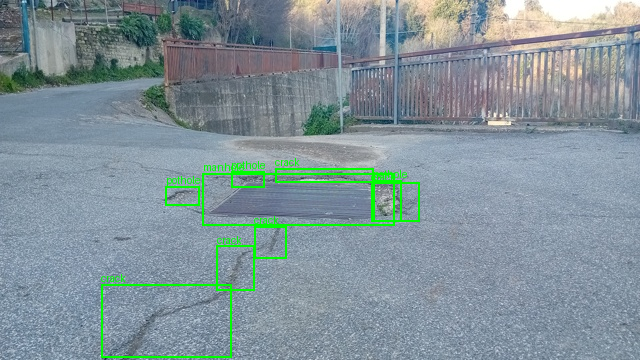

In [4]:
if run_stage("labels"):
    from IPython.display import display, Image as NotebookImage
    display(NotebookImage(filename=str(REPO / "report/figures/train_ground_truth.png")))

## 3. E0 — zero-shot inference and original test scorer
NF4 LLM; vision and lm_head remain unquantized. Predictions: work/e0_test.jsonl.

In [5]:
run_stage("e0")


===== START e0 =====

Fetching 2 files: 100%|██████████| 2/2 [00:45<00:00, 22.77s/it]

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 96.51it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
e0 test: 1/311 images completed
e0 test: 5/311 images completed
e0 test: 10/311 images completed
e0 test: 15/311 images completed
e0 test: 20/311 images completed
e0 test: 25/311 images completed
e0 test: 30/311 images completed
e0 test: 35/311 images completed
e0 test: 40/311 images completed
e0 test: 45/311 images completed
e0 test: 50/311 images completed
e0 test: 55/311 images completed
e0 test: 60/311 images completed
e0 test: 65/311 images completed
e0 test: 70/311 images completed
e0 test: 75/311 images completed
e0 test: 80/311 images completed
e0 test: 85/311 images completed
e0 test: 90/311 images completed
e0 test: 95/311 images completed
e0 test: 100/311 images completed


True

## 4. Encode chat examples and verify answer-only loss
Check the prompt prefix, 220 image tokens, and decode exactly the supervised JSON answer.

In [6]:
run_stage("mask")


===== START mask =====
{
  "image_id": "20250216_164325",
  "image_tokens": 220,
  "supervised_text": "[{\"label\":\"crack\",\"bbox_2d\":[430,467,583,506]},{\"label\":\"pothole\",\"bbox_2d\":[361,475,414,522]},{\"label\":\"manhole\",\"bbox_2d\":[317,481,616,625]},{\"label\":\"pothole\",\"bbox_2d\":[583,500,627,614]},{\"label\":\"crack\",\"bbox_2d\":[580,508,655,614]},{\"label\":\"pothole\",\"bbox_2d\":[259,517,311,572]},{\"label\":\"crack\",\"bbox_2d\":[397,628,447,717]},{\"label\":\"crack\",\"bbox_2d\":[339,683,398,808]},{\"label\":\"crack\",\"bbox_2d\":[158,789,361,994]}]",
  "input_shapes": {
    "input_ids": [
      1,
      552
    ],
    "attention_mask": [
      1,
      552
    ],
    "mm_token_type_ids": [
      1,
      552
    ],
    "pixel_values": [
      880,
      1536
    ],
    "image_grid_thw": [
      1,
      3
    ],
    "labels": [
      1,
      552
    ]
  }
}
===== DONE mask =====


True

## 5. Configure E1/E2/E3 and inspect LoRA targets
E1: LLM LoRA. E2: add full fp32 projector training. E3: add ViT LoRA. Training asserts 252/348 matched modules.

In [7]:
run_stage("configs")


===== START configs =====
LLM LoRA targets: model\.language_model\.layers\.\d+\.(?:self_attn\.(?:q|k|v|o)_proj|mlp\.(?:gate|up|down)_proj)
ViT LoRA targets (E3): model\.visual\.blocks\.\d+\.(?:attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))
e1 {"name": "E1", "description": "LoRA chỉ trên LLM; đóng băng ViT và projector.", "model_id": "Qwen/Qwen3-VL-4B-Instruct", "quantization": "nf4-4bit", "lora": {"r": 16, "alpha": 32, "dropout": 0.05, "targets": "llm"}, "train_projector": false, "lr": 0.0002, "batch_size": 1, "grad_accum": 8, "max_steps": 300, "seed": 42}
e2 {"name": "E2", "description": "E1 + mở đầy đủ projector (visual.merger và visual.deepstack_merger_list).", "model_id": "Qwen/Qwen3-VL-4B-Instruct", "quantization": "nf4-4bit", "lora": {"r": 16, "alpha": 32, "dropout": 0.05, "targets": "llm"}, "train_projector": true, "lr": 0.0002, "batch_size": 1, "grad_accum": 8, "max_steps": 300, "seed": 42}
e3 {"name": "E3", "description": "E2 + LoRA trên các khối attention và MLP của ViT.

True

## 6. Train E1, E2 and E3
Each cell runs 300 optimizer steps, batch 1 × accumulation 8, warmup/cosine and finite loss/gradient checks. Save resumable optimizer/model/RNG/batch checkpoints every 50 successful steps. Compatible completed setups are reused; interrupted training resumes at its last complete checkpoint. Final artifacts contain LoRA plus full projector weights for E2/E3.

In [8]:
# Train E1 and record real VRAM/time/loss.
run_stage("train", "e1")


===== START train_e1 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 98.70it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
Trainable groups (all fp32): {"llm_lora": 33030144, "vit_lora": 0, "projector": 0}
trainable params: 33,030,144 || all params: 4,470,845,952 || trainable%: 0.7388
e1 {'step': 10, 'attempt': 10, 'loss': 0.7747015357017517, 'grad_norm': 0.6782175302505493, 'lr': 0.00014666666666666666}
e1 {'step': 20, 'attempt': 20, 'loss': 0.6999422684311867, 'grad_norm': 0.5910031199455261, 'lr': 0.00019984815164333163}
e1 {'step': 30, 'attempt': 30, 'loss': 0.6360368803143501, 'grad_norm': 0.5989707708358765, 'lr': 0.00019863613034027224}
e1 {'step': 40, 'attempt': 40, 'loss': 0.6359123066067696, 'grad_norm': 0.44976991415023804, 'lr': 0.00019622680003092503}
e1 {'step': 50, 'attempt': 50, 'loss': 0.6068757846951485, 'grad_norm': 0.4370257556438446, 'lr': 0

True

In [9]:
# Train E2 and record real VRAM/time/loss.
run_stage("train", "e2")


===== START train_e2 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 96.67it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
Trainable groups (all fp32): {"llm_lora": 33030144, "vit_lora": 0, "projector": 109105152}
trainable params: 142,135,296 || all params: 4,470,845,952 || trainable%: 3.1792
e2 {'step': 10, 'attempt': 10, 'loss': 0.7764237076044083, 'grad_norm': 0.9829753041267395, 'lr': 0.00014666666666666666}
e2 {'step': 20, 'attempt': 20, 'loss': 0.694786049425602, 'grad_norm': 0.7818779349327087, 'lr': 0.00019984815164333163}
e2 {'step': 30, 'attempt': 30, 'loss': 0.7017675042152405, 'grad_norm': 0.691508948802948, 'lr': 0.00019863613034027224}
e2 {'step': 40, 'attempt': 40, 'loss': 0.6431176997721195, 'grad_norm': 0.48342710733413696, 'lr': 0.00019622680003092503}
e2 {'step': 50, 'attempt': 50, 'loss': 0.6015194579958916, 'grad_norm': 0.5288698077201843, 

True

In [10]:
# Train E3 and record real VRAM/time/loss.
run_stage("train", "e3")


===== START train_e3 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 95.24it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
Trainable groups (all fp32): {"llm_lora": 33030144, "vit_lora": 6291456, "projector": 109105152}
trainable params: 148,426,752 || all params: 4,477,137,408 || trainable%: 3.3152
e3: AMP overflow; retry step 3 at scale 32768.0
e3 {'step': 10, 'attempt': 11, 'loss': 0.7687541767954826, 'grad_norm': 1.1021203994750977, 'lr': 0.00014666666666666666}
e3 {'step': 20, 'attempt': 21, 'loss': 0.6627954840660095, 'grad_norm': 1.7132426500320435, 'lr': 0.00019984815164333163}
e3: AMP overflow; retry step 25 at scale 16384.0
e3 {'step': 30, 'attempt': 32, 'loss': 0.6315230205655098, 'grad_norm': 3.3284482955932617, 'lr': 0.00019863613034027224}
e3 {'step': 40, 'attempt': 42, 'loss': 0.5999231785535812, 'grad_norm': 6.175820827484131, 'lr': 0.00019622680

True

## 7. Reload adapters/projectors, infer and score E1–E3
Each setup is evaluated on val and test. E4 base selection uses val only. Evidence uses the unmodified scripts/score.py.

In [11]:
run_stage("evaluate", "e1")


===== START evaluate_e1 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 95.63it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
e1 val: 1/276 images completed
e1 val: 5/276 images completed
e1 val: 10/276 images completed
e1 val: 15/276 images completed
e1 val: 20/276 images completed
e1 val: 25/276 images completed
e1 val: 30/276 images completed
e1 val: 35/276 images completed
e1 val: 40/276 images completed
e1 val: 45/276 images completed
e1 val: 50/276 images completed
e1 val: 55/276 images completed
e1 val: 60/276 images completed
e1 val: 65/276 images completed
e1 val: 70/276 images completed
e1 val: 75/276 images completed
e1 val: 80/276 images completed
e1 val: 85/276 images completed
e1 val: 90/276 images completed
e1 val: 95/276 images completed
e1 val: 100/276 images completed
e1 val: 105/276 images completed
e1 val: 110/276 images completed
e1 val: 115

True

In [12]:
run_stage("evaluate", "e2")


===== START evaluate_e2 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 94.14it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
e2 val: 1/276 images completed
e2 val: 5/276 images completed
e2 val: 10/276 images completed
e2 val: 15/276 images completed
e2 val: 20/276 images completed
e2 val: 25/276 images completed
e2 val: 30/276 images completed
e2 val: 35/276 images completed
e2 val: 40/276 images completed
e2 val: 45/276 images completed
e2 val: 50/276 images completed
e2 val: 55/276 images completed
e2 val: 60/276 images completed
e2 val: 65/276 images completed
e2 val: 70/276 images completed
e2 val: 75/276 images completed
e2 val: 80/276 images completed
e2 val: 85/276 images completed
e2 val: 90/276 images completed
e2 val: 95/276 images completed
e2 val: 100/276 images completed
e2 val: 105/276 images completed
e2 val: 110/276 images completed
e2 val: 115

True

In [13]:
run_stage("evaluate", "e3")


===== START evaluate_e3 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 97.89it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
e3 val: 1/276 images completed
e3 val: 5/276 images completed
e3 val: 10/276 images completed
e3 val: 15/276 images completed
e3 val: 20/276 images completed
e3 val: 25/276 images completed
e3 val: 30/276 images completed
e3 val: 35/276 images completed
e3 val: 40/276 images completed
e3 val: 45/276 images completed
e3 val: 50/276 images completed
e3 val: 55/276 images completed
e3 val: 60/276 images completed
e3 val: 65/276 images completed
e3 val: 70/276 images completed
e3 val: 75/276 images completed
e3 val: 80/276 images completed
e3 val: 85/276 images completed
e3 val: 90/276 images completed
e3 val: 95/276 images completed
e3 val: 100/276 images completed
e3 val: 105/276 images completed
e3 val: 110/276 images completed
e3 val: 115

True

## 8. E4 rank ablation, report artifacts and GitHub push
Choose the base using validation F1, then change only rank (alpha=2×rank): 4 and 64. E5 is excluded.

In [14]:
run_stage("select-e4")


===== START select-e4 =====
E4 base selected on validation: e3; compare rank 4 vs 64
===== DONE select-e4 =====


True

In [15]:
if run_stage("train", "e4_rank_4"):
    run_stage("evaluate", "e4_rank_4")


===== START train_e4_rank_4 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 96.94it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
Trainable groups (all fp32): {"llm_lora": 8257536, "vit_lora": 1572864, "projector": 109105152}
trainable params: 118,935,552 || all params: 4,447,646,208 || trainable%: 2.6741
e4_rank_4 {'step': 10, 'attempt': 10, 'loss': 0.794038251042366, 'grad_norm': 1.192311406135559, 'lr': 0.00014666666666666666}
e4_rank_4: AMP overflow; retry step 12 at scale 32768.0
e4_rank_4: AMP overflow; retry step 13 at scale 16384.0
e4_rank_4: AMP overflow; retry step 20 at scale 8192.0
e4_rank_4 {'step': 20, 'attempt': 23, 'loss': 0.7040595449507236, 'grad_norm': 0.9329557418823242, 'lr': 0.00019984815164333163}
e4_rank_4 {'step': 30, 'attempt': 33, 'loss': 0.6820265799760818, 'grad_norm': 0.5787441730499268, 'lr': 0.00019863613034027224}
e4_rank_4 {'ste

In [16]:
if run_stage("train", "e4_rank_64"):
    run_stage("evaluate", "e4_rank_64")


===== START train_e4_rank_64 =====

Loading weights: 100%|██████████| 713/713 [00:07<00:00, 96.84it/s] 
Quantization verified: {"skip_modules": ["model.visual", "lm_head"], "vision_params": 415347712, "projector_params": 109105152, "nf4_llm_weights": 252}
Trainable groups (all fp32): {"llm_lora": 132120576, "vit_lora": 25165824, "projector": 109105152}
trainable params: 266,391,552 || all params: 4,595,102,208 || trainable%: 5.7973
e4_rank_64 {'step': 10, 'attempt': 10, 'loss': 0.7603346332907677, 'grad_norm': 4.197277069091797, 'lr': 0.00014666666666666666}
e4_rank_64: AMP overflow; retry step 17 at scale 32768.0
e4_rank_64 {'step': 20, 'attempt': 21, 'loss': 0.6127229258418083, 'grad_norm': 2.070510149002075, 'lr': 0.00019984815164333163}
e4_rank_64 {'step': 30, 'attempt': 31, 'loss': 0.6412322819232941, 'grad_norm': 2.7472147941589355, 'lr': 0.00019863613034027224}
e4_rank_64 {'step': 40, 'attempt': 41, 'loss': 0.6724754609167576, 'grad_norm': 1.8774555921554565, 'lr': 0.0001962268

In [17]:
if run_stage("summary"):
    from IPython.display import display, Markdown
    display(Markdown((REPO / "report/RESULTS.md").read_text(encoding="utf-8")))
    print((REPO / "report/submission_check.txt").read_text(encoding="utf-8"))


===== START summary =====
===== DONE summary =====


| Setup | F1 | CI95 | FP/image | pothole | crack | manhole | VRAM GB | Train min |
|---|---|---|---|---|---|---|---|---|
| e0 | 0.0458 | [0.03122878479293958, 0.06278713629402756] | 2.2379 | 0.0984 | 0.0028 | 0.0985 | N/A | N/A |
| e1 | 0.2799 | [0.2433862433862434, 0.317048853439681] | 1.1093 | 0.2073 | 0.2082 | 0.5159 | 5.0458 | 47.0102 |
| e2 | 0.3533 | [0.3109919571045576, 0.3934126258005489] | 1.0032 | 0.1914 | 0.2998 | 0.5978 | 6.7057 | 48.4339 |
| e3 | 0.4111 | [0.36837209302325585, 0.4541832669322709] | 0.7846 | 0.2365 | 0.3502 | 0.6549 | 6.8406 | 58.2211 |
| e4_rank_4 | 0.4152 | [0.3734827264239029, 0.45817490494296575] | 0.8746 | 0.2755 | 0.3266 | 0.6920 | 6.4011 | 58.0211 |
| e4_rank_64 | 0.4269 | [0.3847517730496454, 0.4680451127819549] | 0.8746 | 0.2949 | 0.3515 | 0.6831 | 8.7926 | 60.0300 |


[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 9/5
[PASS] git forbidden files

1 FAIL, 0 WARN



In [18]:
# Push only report artifacts. Weights, data and secrets stay out of GitHub.
from student.github_sync import push_results
if not GITHUB_TOKEN:
    GITHUB_TOKEN = UserSecretsClient().get_secret("GITHUB_TOKEN")
push_error = None
try:
    push_results(REPO, GITHUB_TOKEN, RESULT_BRANCH)
except Exception as exc:
    push_error = exc
    print("GitHub push failed; download report/ from Kaggle Output.")
finally:
    GITHUB_TOKEN = None
if pipeline_error is not None:
    print("PIPELINE FAILED:", pipeline_error)
    print("Partial results/checkpoints are kept in Kaggle Output. Attach this Output as Input in the next version and set RESUME_FROM.")
elif push_error is not None:
    print("Pipeline finished; GITHUB PUSH FAILED. Download report/ from Kaggle Output.")
else:
    print("Completed. Pull branch", RESULT_BRANCH, "at local to finish REPORT.md.")
if FAIL_VERSION_ON_ERROR:
    if pipeline_error is not None:
        raise pipeline_error
    if push_error is not None:
        raise push_error

GitHub push failed; download report/ from Kaggle Output.
Pipeline finished; GITHUB PUSH FAILED. Download report/ from Kaggle Output.
